# SPUS v2 tutorial workflow

This notebook is organized into five sections:

1. looking at the data
2. pretrained-only baseline inference with `spus-pde-unet-36m-v2`
3. fine-tuned inference with `spus-pde-unet-36m-v2-fns-kf-25`
4. user fine-tuning from the pretrained baseline
5. inference and evaluation of the user checkpoint
6. optional comparison against the pretrained baseline, three fine-tuned models and a from-scratch model


In [1]:
%load_ext autoreload
%autoreload 1
from pathlib import Path
from spus_ft import (
    evaluate_rollout,
    fine_tune,
    infer_rollout,
    plot_multiple_rollout_mse_curves,
    plot_rollout_frames,
    plot_rollout_mse_curve,
)

# Change this if your tutorial repo `ft_tut` and `tut-aux` live somewhere else.
WORKSPACE_ROOT = Path("/home/ubuntu/workspace")
# Example local alternative:
#WORKSPACE_ROOT = Path("/vast/projects/artimis/cahrens")

AUX_ROOT = WORKSPACE_ROOT / "tut-aux"
REPO_ROOT = WORKSPACE_ROOT / "ft_tut"

dataset_path = AUX_ROOT / "spus-ft-data" / "FNS-KF" / "FNS-KF.nc"
models_root = AUX_ROOT / "spus-models"
comparison_output_dir = AUX_ROOT / "spus-ft-runs"

pretrained_v2_model_dir_36m = models_root / "spus-pde-unet-36m-v2"
pretrained_v2_model_dir_9m = models_root / "spus-pde-unet-9m-v2"
pretrained_v2_model_dir_36m_lowdata = models_root / "spus-pde-unet-36m-v2-one-eighth-pretraining-data"

finetuned_model_dir_32 = models_root / "spus-pde-unet-36m-v2-fns-kf-32"
finetuned_model_dir_128 = models_root / "spus-pde-unet-36m-v2-fns-kf"
finetuned_model_dir_256 = models_root / "spus-pde-unet-36m-v2-fns-kf-256"

from_scratch_fns_kf_model_dir = models_root / "spus-pde-unet-36m-fns-kf-scratch-128"

fns_kf_channel_names = [
    "horizontal velocity",
    "vertical velocity",
    "padding channel 2",
    "padding channel 3",
    "padding channel 4",
]

def print_outcome_summary(name, outcome):
    print(f"{name}:")
    for key in ("run_dir", "checkpoint_path", "predictions_path", "evaluation_path"):
        value = outcome.get(key)
        if value is not None:
            print(f"  {key}: {value}")


**Channel note**

For FNS-KF, only channels `0` and `1` are physical variables: `horizontal velocity` and `vertical velocity`.
Channels `2`, `3`, and `4` are constant padding channels added so the data matches the 5-channel SPUS input format, so they should not be interpreted physically and will look visually blank or uniform in plots.


## 1 Looking at the data

Before running baseline inference or fine-tuning, we first make a couple of simple trajectory plots so people get a sense of what the FNS-KF data looks like and how much data there is.

The assembled `FNS-KF.nc` file contains **20,000 trajectories**, each with **21 time steps**, **2 physical channels** (`horizontal velocity` and `vertical velocity`), and a **128 × 128** spatial grid.

These plots are meant as a quick visual orientation step before we move on to baseline inference, user fine-tuning, and model comparison.


/vast/projects/artimis/cahrens/tut/src/spus_ft/plotting.py:512: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout(rect=(0.0, 0.12, 1.0, 0.88))


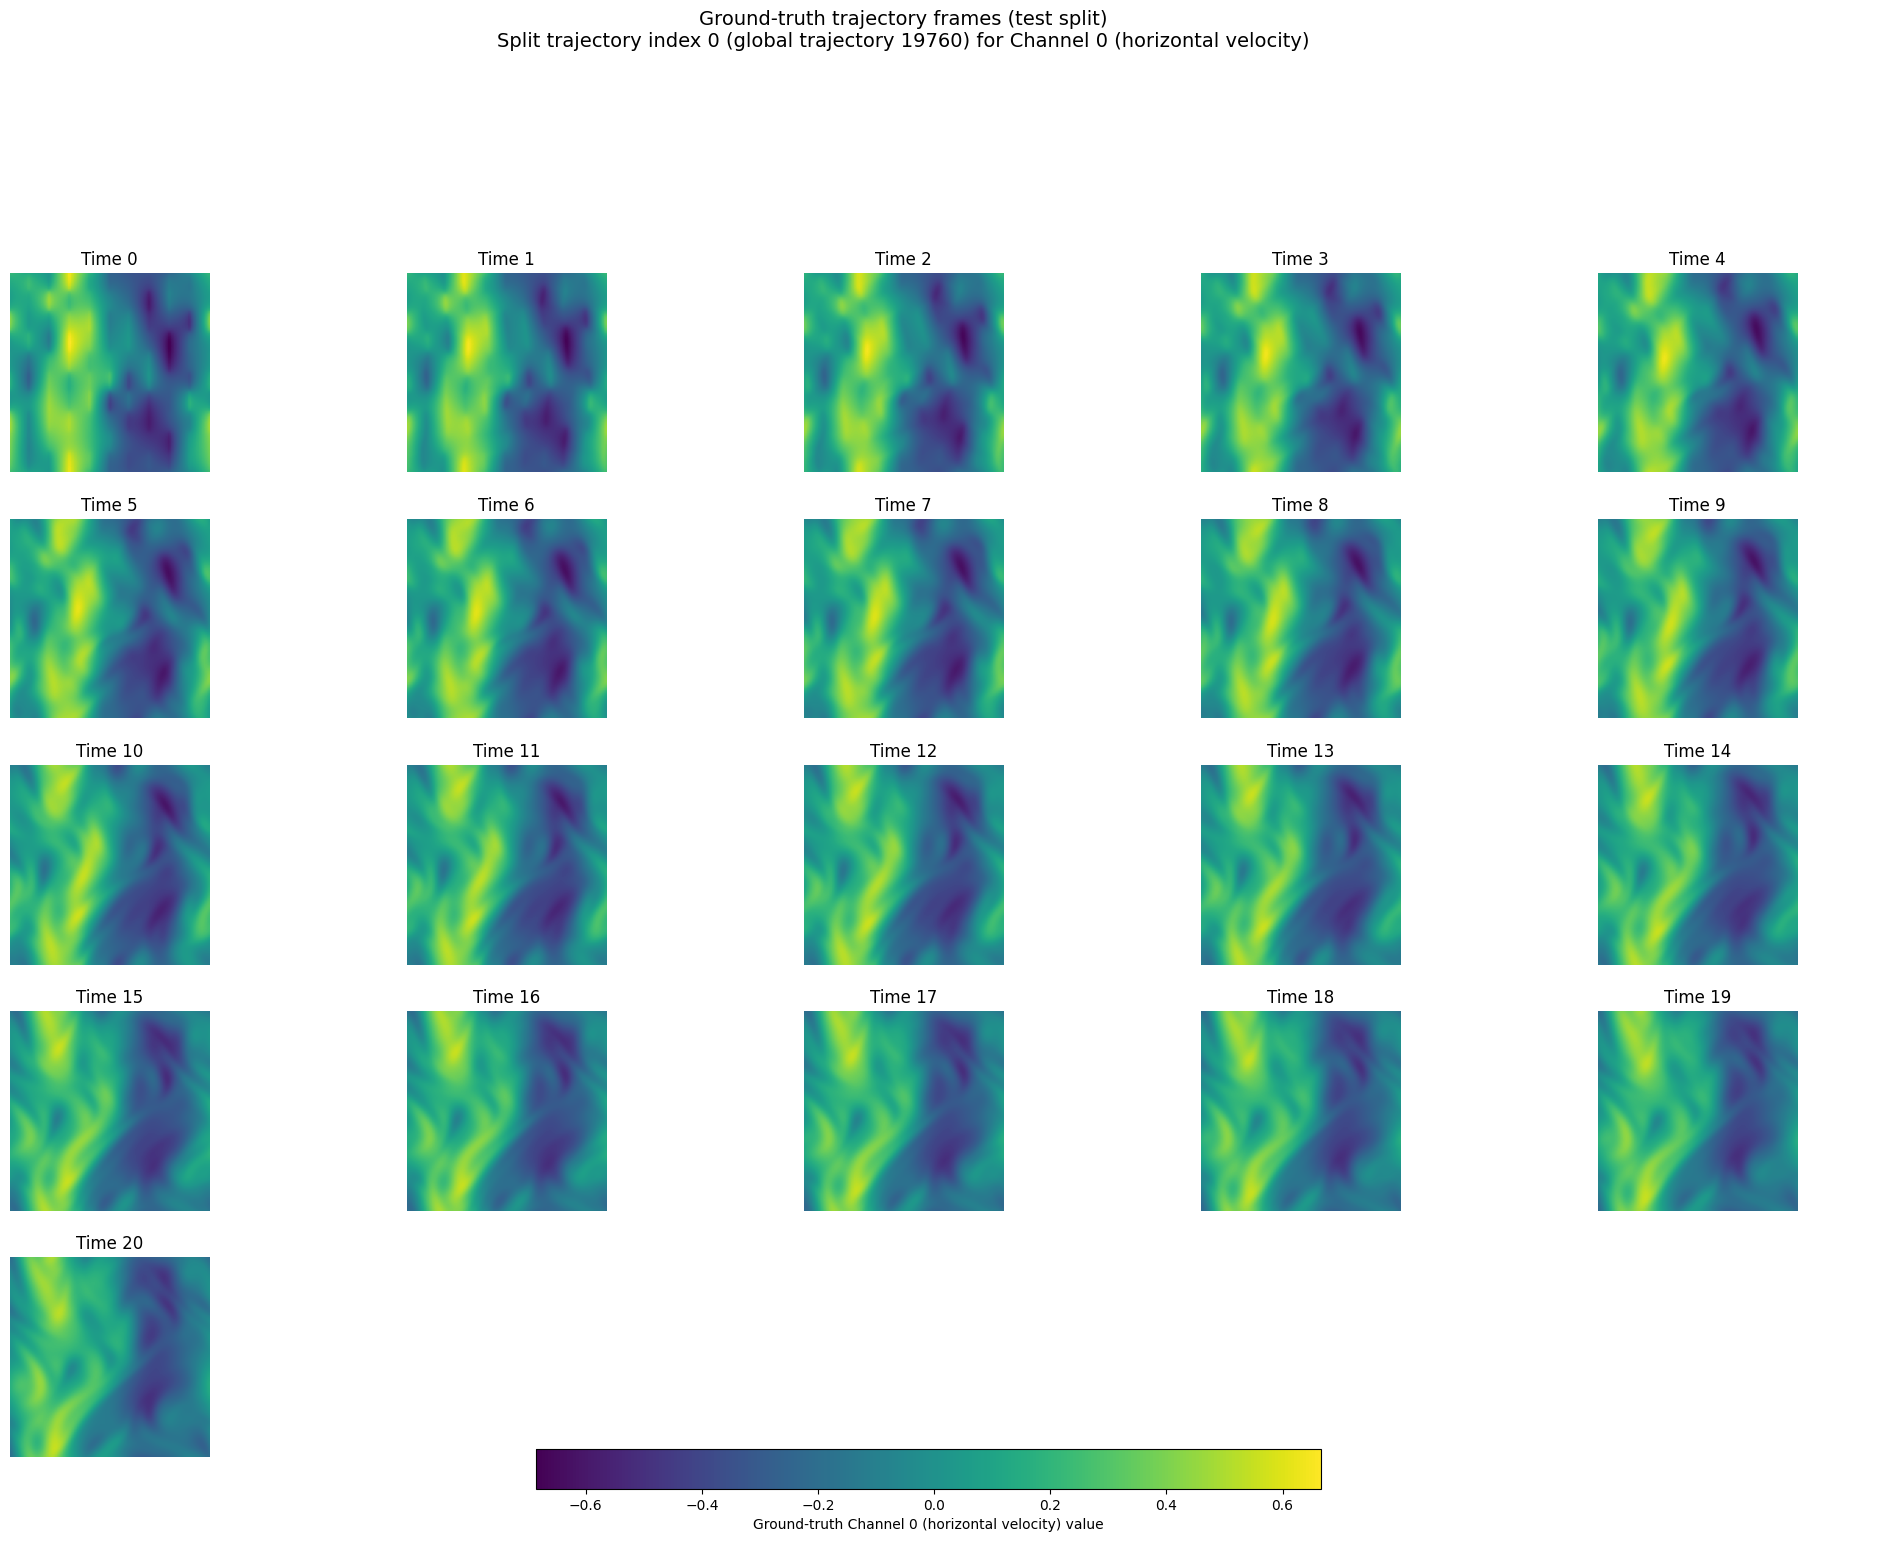

In [2]:
# Plot a trajectory to get a sense of what is in there
from spus_ft import plot_ground_truth_trajectory_frames

_=plot_ground_truth_trajectory_frames(
    dataset_path=dataset_path,
    split_name="test",
    split_trajectory_index=0,
    channel_index=0,
    channel_names=fns_kf_channel_names,
    max_columns=5,
    save_path=comparison_output_dir / "test_truth_traj0_ch0.png",
)


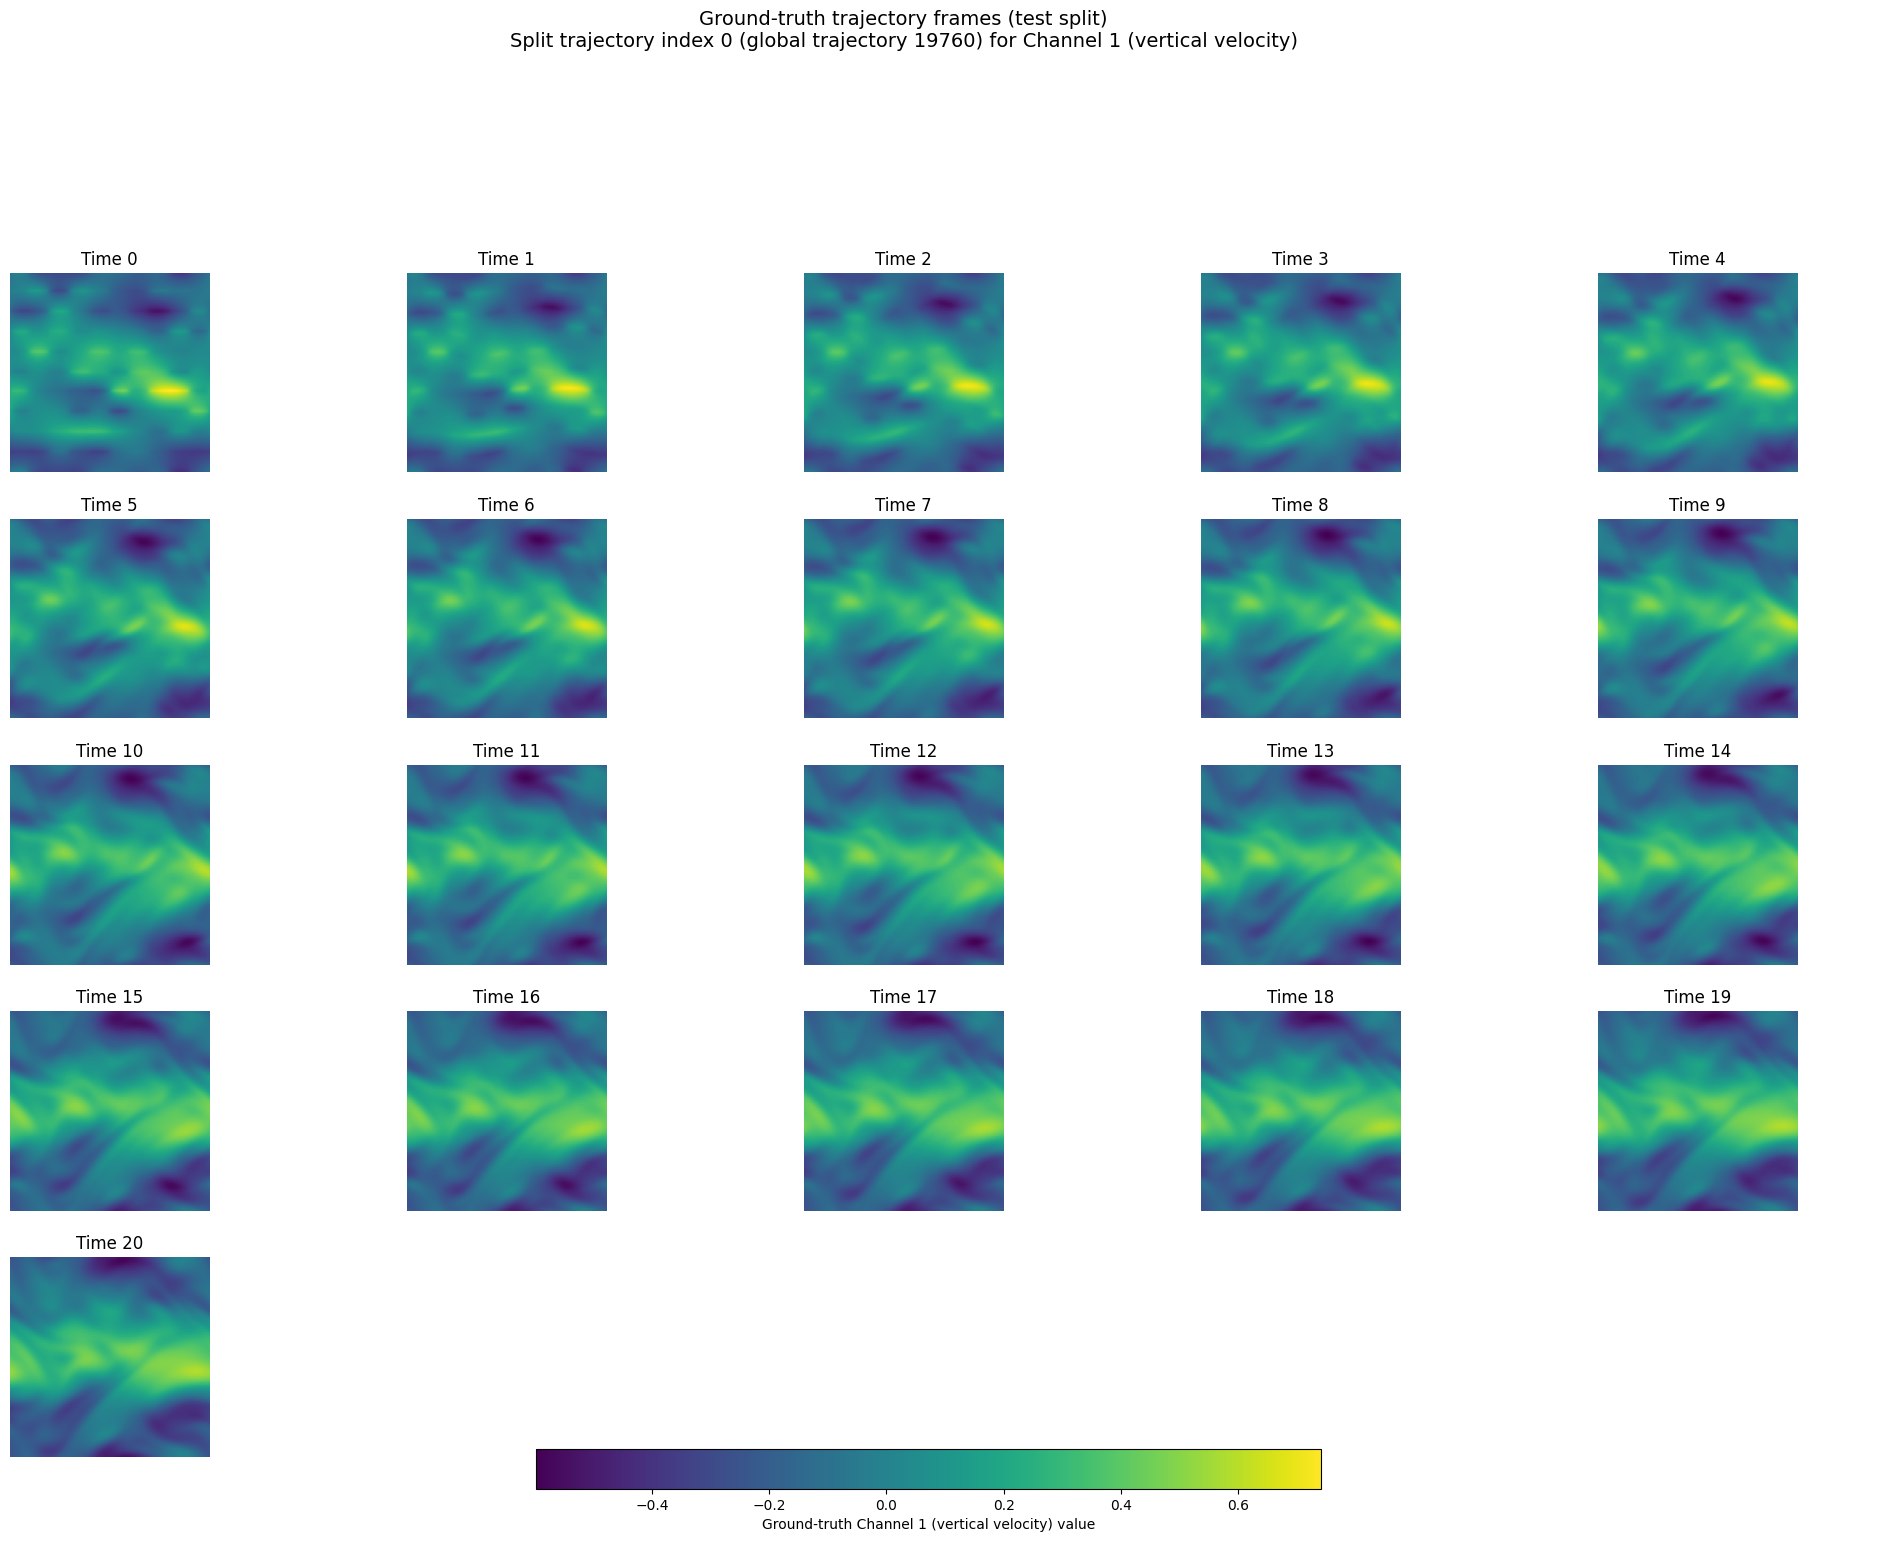

In [3]:
# Plot the same test trajectory for channel 1 (vertical velocity)
_=plot_ground_truth_trajectory_frames(
    dataset_path=dataset_path,
    split_name="test",
    split_trajectory_index=0,
    channel_index=1,
    channel_names=fns_kf_channel_names,
    max_columns=5,
    save_path=comparison_output_dir / "test_truth_traj0_ch1.png",
)


## 2. Pretrained-only inference with `spus-pde-unet-36m-v2`

Run one autoregressive rollout with the pretrained SPUS U-Net v2 baseline on a test FNS-KF trajectory. This will likely not have a good result because the model has not been finetuned on any FNS-KF data yet.


In [4]:
pretrained_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=pretrained_v2_model_dir_36m,
)
print_outcome_summary("Pretrained baseline rollout", pretrained_rollout_outcome)


/vast/projects/artimis/cahrens/tut/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights from local directory
Pretrained baseline rollout:
  run_dir: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_pretrained_20261106-230608
  predictions_path: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_pretrained_20261106-230608/rollout.pt


/vast/projects/artimis/cahrens/tut/src/spus_ft/plotting.py:300: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout(rect=(0.0, 0.19, 1.0, 0.93), h_pad=2.0)


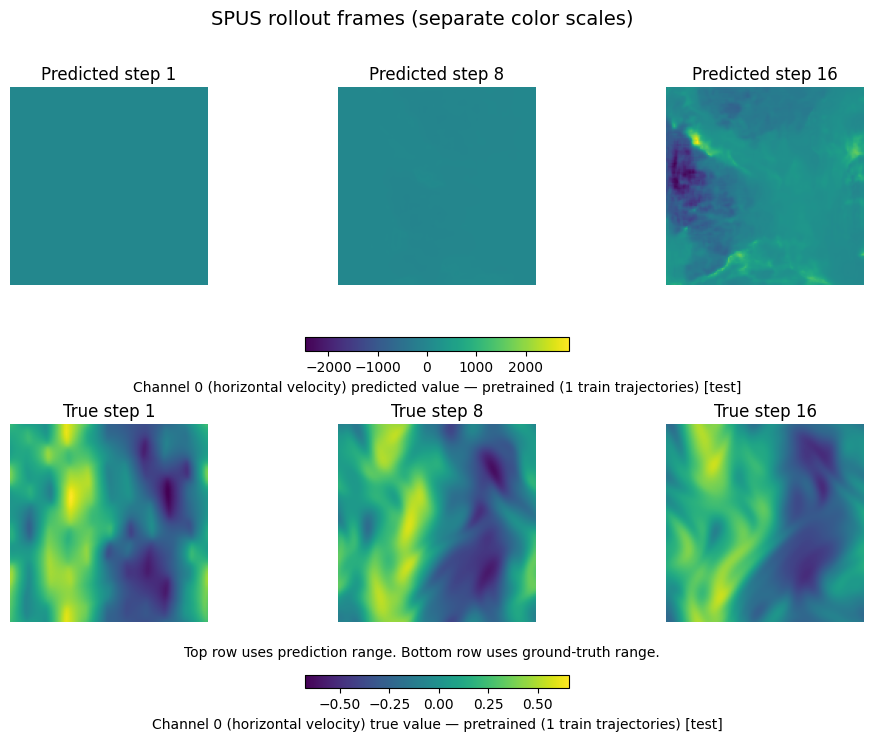

In [5]:
from spus_ft import plot_rollout_frames_separate_scales

_ = plot_rollout_frames_separate_scales(
    run_dir=pretrained_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
    save_path=pretrained_rollout_outcome["run_dir"] / "pretrained_v2_fig3_like_separate_scales.png",
)


## 3. Fine-tuned inference with `spus-pde-unet-36m-v2-fns-kf-256`

Run one autoregressive rollout with the fine-tuned (on 256 trajectories) SPUS U-Net v2 model on a test FNS-KF trajectory. This will have a much better result.


In [6]:
# Predict using model fine-tuned with 256 trajectories.
finetuned_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=finetuned_model_dir_256,
)
print_outcome_summary("HF fine-tuned rollout (256 trajectories)", finetuned_rollout_outcome)


Loading weights from local directory
HF fine-tuned rollout (256 trajectories):
  run_dir: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261106-230611
  predictions_path: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261106-230611/rollout.pt


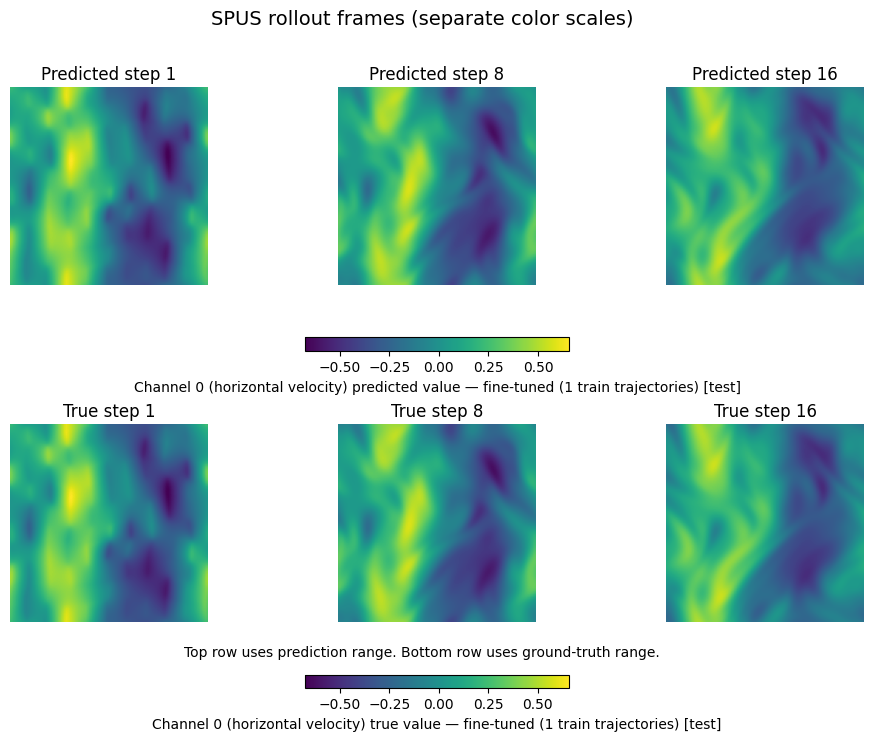

In [7]:
#show the fine-tuned model predictions

from spus_ft import plot_rollout_frames_separate_scales

_ = plot_rollout_frames_separate_scales(
    run_dir=finetuned_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
)


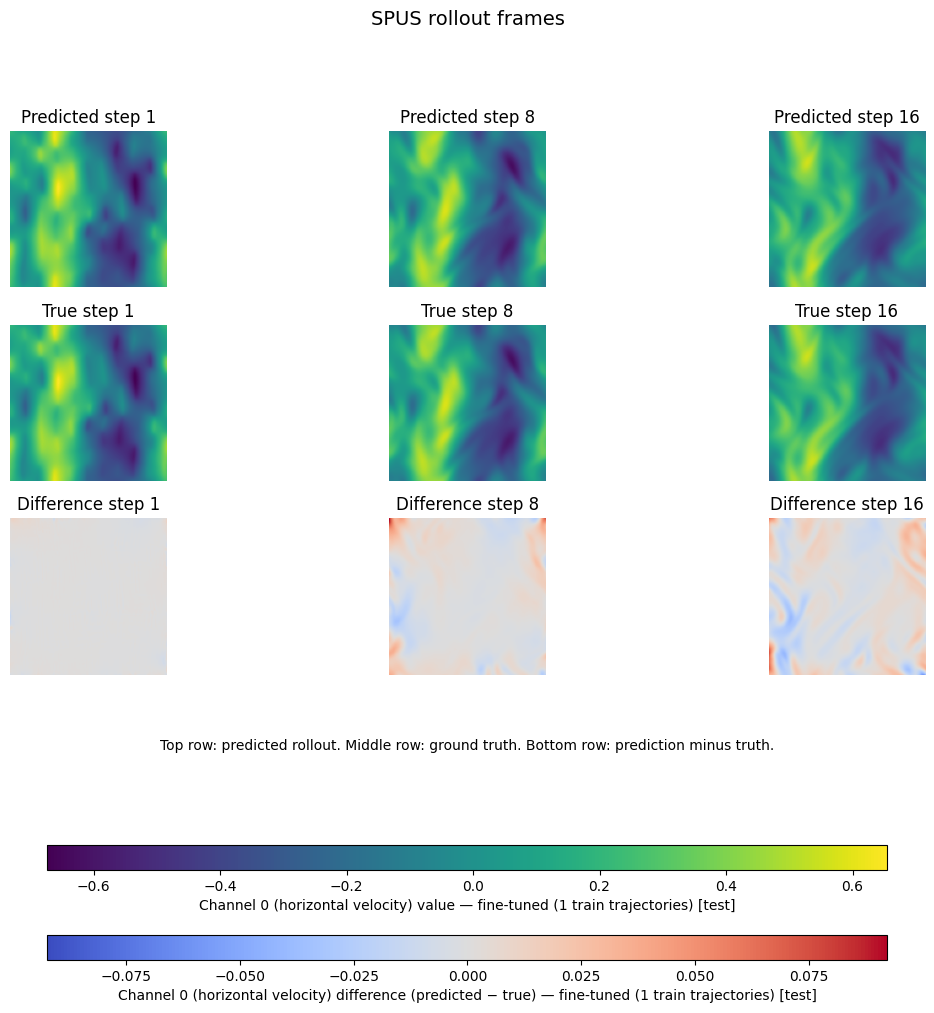

In [8]:
# Show the fine-tuned model predictions with differences
from spus_ft import plot_rollout_frames_separate_scales

_ = plot_rollout_frames(
    run_dir=finetuned_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
)


In [9]:
from spus_ft.results import load_torch_rollout, summarize_rollout_prediction_range
import torch

payload = load_torch_rollout(pretrained_rollout_outcome["run_dir"], torch_module=torch)
range_summary = summarize_rollout_prediction_range(payload["predictions"])
print(range_summary)

{'min': -21923.56640625, 'max': 36931.9375}


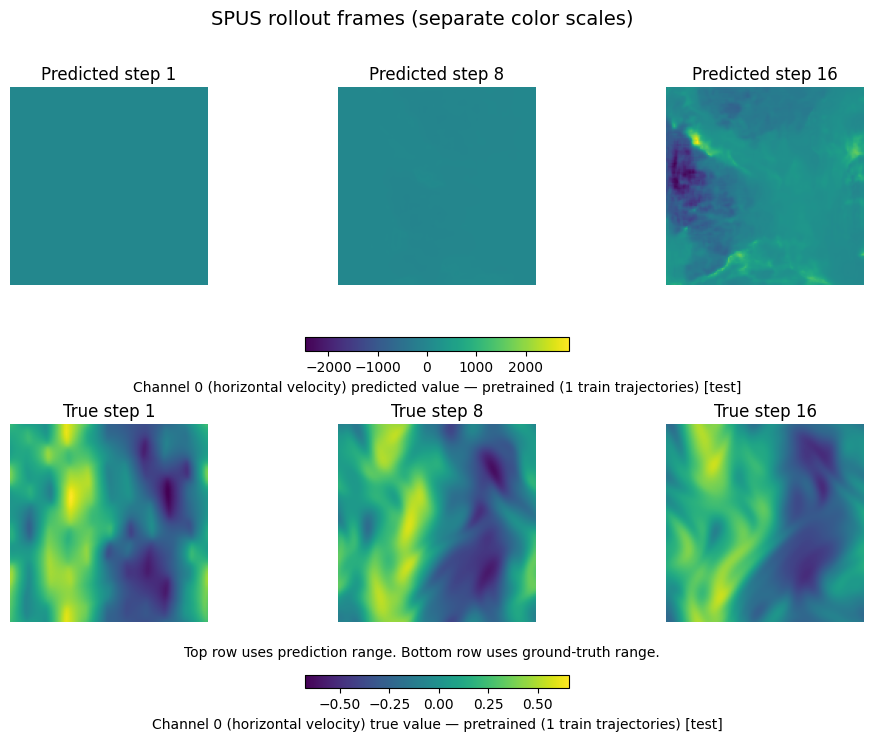

In [10]:
from spus_ft import plot_rollout_frames_separate_scales

_ = plot_rollout_frames_separate_scales(
    run_dir=pretrained_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
    save_path=pretrained_rollout_outcome["run_dir"] / "pretrained_v2_fig3_like_separate_scales.png",
)


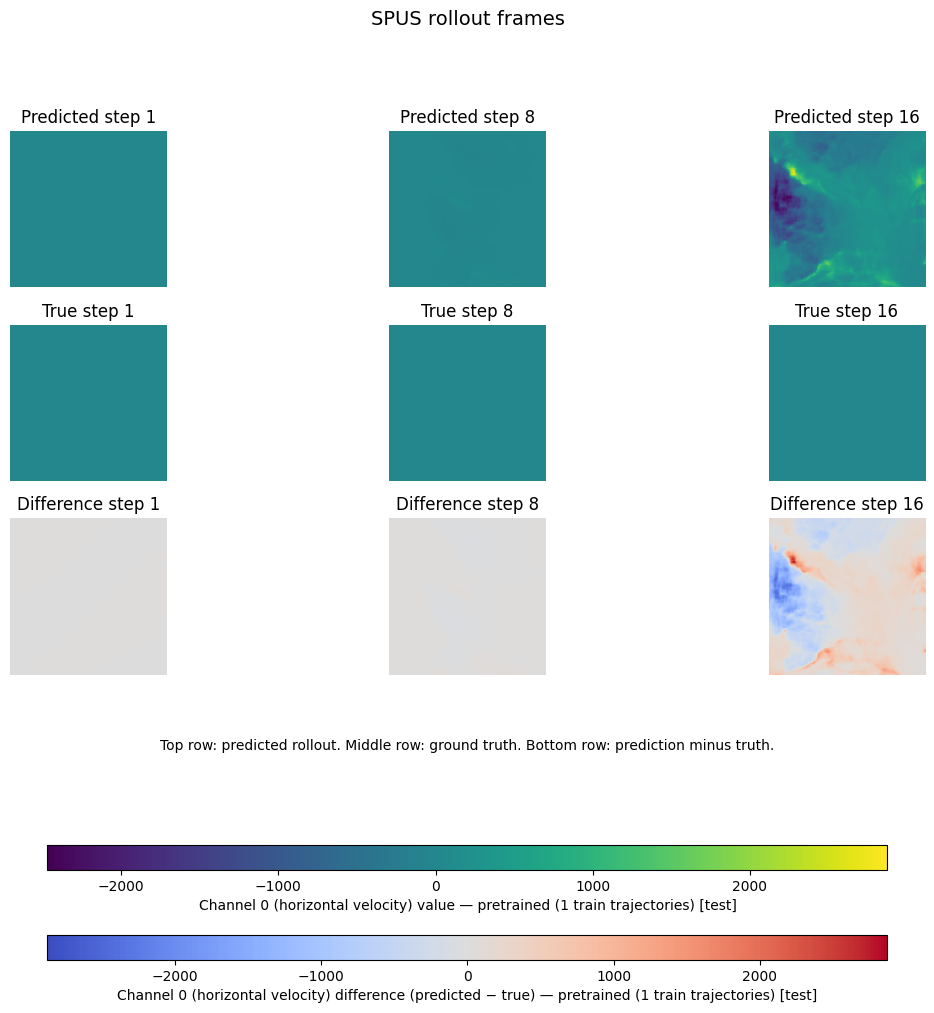

In [11]:
_ = plot_rollout_frames(
    run_dir=pretrained_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
    save_path=pretrained_rollout_outcome["run_dir"] / "pretrained_v2_fig3_like_rollout.png",
)


## 4. User fine-tuning from the 36m parameter v2 pretrained model

Fine-tune the pretrained SPUS U-Net v2 36m parameter model on FNS-KF and save the resulting checkpoint into `spus-ft-runs`.


In [12]:
finetune_outcome = fine_tune(
    dataset_path=dataset_path,
    pretrained_source=pretrained_v2_model_dir_36m,
    num_train_trajectories=16,
    epochs=10,
    echo_logs=True,
)
print_outcome_summary("User fine-tune run", finetune_outcome)


[2026-11-06 23:06:16] Constructed in-memory train/val/test trajectory splits from assembled NetCDF file /vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc: variable=solution, shape=(20000, 21, 2, 128, 128), split_strategy=fns_kf_paper, train_trajectories=16, val_trajectories=120, test_trajectories=240, target_channels=5, pad_value=1.0
[2026-11-06 23:06:16] Created data loaders: train_batches=80, val_batches=600, batch_size=4, num_workers=0
Loading weights from local directory
[2026-11-06 23:06:18] Starting fine-tune: dataset=/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc, pretrained_source=/vast/projects/artimis/cahrens/tut-aux/spus-models/spus-pde-unet-36m-v2, epochs=10, batch_size=4, learning_rate=0.0001, train_trajectories=16, val_trajectories=120, test_trajectories=240, device=cuda
[2026-11-06 23:06:18] Starting epoch 1/10
[2026-11-06 23:06:27] Completed epoch 1/10: train_loss=0.019705, val_loss=0.000661
[2026-11-06 23:06:27] New best checkpoint at epoch 1: val_loss=0

### Fine-tuning metrics
Review how much training data was used and how long the fine-tuning run took.


In [13]:
fine_tune_metrics = finetune_outcome["fine_tune_metrics"]
print("Captured fine-tuning metrics in `fine_tune_metrics`.")
print("Use the next cell for a human-readable summary.")


Captured fine-tuning metrics in `fine_tune_metrics`.
Use the next cell for a human-readable summary.


### Fine-tuning summary
A short, human-readable summary of the fine-tuning run.


In [14]:
metrics = finetune_outcome["fine_tune_metrics"]
print(f"Requested training trajectories: {metrics['requested_num_train_trajectories']}")
print(f"Training trajectories used: {metrics['num_train_trajectories']}")
print(f"Validation trajectories: {metrics['num_val_trajectories']}")
print(f"Test trajectories: {metrics['num_test_trajectories']}")
print(f"Training samples: {metrics['num_train_samples']}")
print(f"Validation samples: {metrics['num_val_samples']}")
print(f"Batches per training epoch: {metrics['num_train_batches_per_epoch']}")
print(f"Batches per validation epoch: {metrics['num_val_batches_per_epoch']}")
print(f"Fine-tuning started at: {metrics['fine_tune_started_at']}")
print(f"Fine-tuning finished at: {metrics['fine_tune_finished_at']}")
print(f"Fine-tuning duration: {metrics['fine_tune_duration_seconds']:.2f} seconds ({metrics['fine_tune_duration_minutes']:.2f} minutes)")


Requested training trajectories: 16
Training trajectories used: 16
Validation trajectories: 120
Test trajectories: 240
Training samples: 320
Validation samples: 2400
Batches per training epoch: 80
Batches per validation epoch: 600
Fine-tuning started at: 2026-11-07T06:06:18Z
Fine-tuning finished at: 2026-11-07T06:07:45Z
Fine-tuning duration: 87.51 seconds (1.46 minutes)


## 5. Inference and evaluation of the user's fine-tuned checkpoint

Run autoregressive inference with your newly fine-tuned checkpoint, then evaluate without rerunning inference.


In [15]:
user_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=pretrained_v2_model_dir_36m,
    checkpoint_path=finetune_outcome["checkpoint_path"],
)
print_outcome_summary("User fine-tuned rollout", user_rollout_outcome)


Loading weights from local directory
User fine-tuned rollout:
  run_dir: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261106-230748
  predictions_path: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261106-230748/rollout.pt


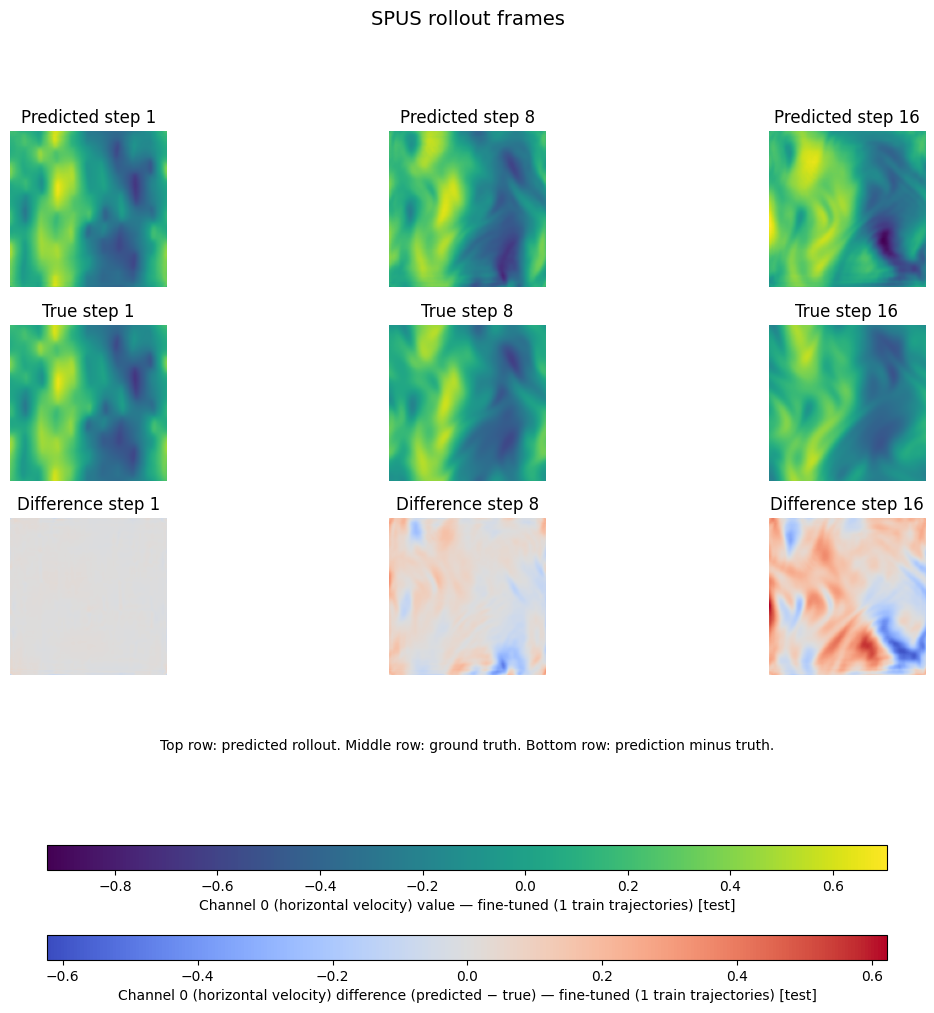

In [16]:
_ = plot_rollout_frames(
    run_dir=user_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
    save_path=user_rollout_outcome["run_dir"] / "user_finetuned_fig3_like_rollout.png",
)


User fine-tuned evaluation:
  run_dir: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261106-230748
  predictions_path: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261106-230748/rollout.pt
  evaluation_path: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261106-230748/evaluation.json


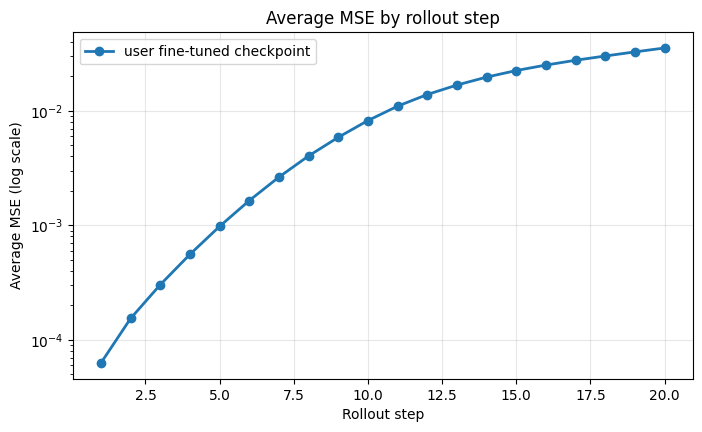

In [17]:
user_evaluation_outcome = evaluate_rollout(
    rollout_outcome=user_rollout_outcome,
)
print_outcome_summary("User fine-tuned evaluation", user_evaluation_outcome)

_ = plot_rollout_mse_curve(
    user_evaluation_outcome["evaluation_path"],
    label="user fine-tuned checkpoint",
)


## 6. Optional comparison against the three Hugging Face fine-tuned models

Evaluate the pretrained v2 baseline and the three published fine-tuned v2 models (32, 128 and 256 trajectories), then compare their rollout MSE curves against your own checkpoint.


In [18]:
pretrained_evaluation_outcome = evaluate_rollout(
    rollout_outcome=pretrained_rollout_outcome,
)

fns_kf_128_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=finetuned_model_dir_128,
)
fns_kf_128_evaluation_outcome = evaluate_rollout(rollout_outcome=fns_kf_128_rollout_outcome)

fns_kf_32_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=finetuned_model_dir_32,
)
fns_kf_32_evaluation_outcome = evaluate_rollout(rollout_outcome=fns_kf_32_rollout_outcome)

fns_kf_256_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=finetuned_model_dir_256,
)
fns_kf_256_evaluation_outcome = evaluate_rollout(rollout_outcome=fns_kf_256_rollout_outcome)

fns_kf_scratch_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=from_scratch_fns_kf_model_dir,
)
fns_kf_scratch_evaluation_outcome = evaluate_rollout(rollout_outcome=fns_kf_scratch_rollout_outcome)

for label, outcome in [
    ("Pretrained baseline evaluation", pretrained_evaluation_outcome),
    ("HF fine-tuned evaluation (32 trajectories)", fns_kf_32_evaluation_outcome),
    ("HF fine-tuned evaluation (128 trajectories)", fns_kf_128_evaluation_outcome),
    ("HF fine-tuned evaluation (256 trajectories)", fns_kf_256_evaluation_outcome),
    ("From-scratch FNS-KF evaluation", fns_kf_scratch_evaluation_outcome),
]:
    print_outcome_summary(label, outcome)


Loading weights from local directory
Loading weights from local directory
Loading weights from local directory
Loading weights from local directory
Pretrained baseline evaluation:
  run_dir: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_pretrained_20261106-230608
  predictions_path: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_pretrained_20261106-230608/rollout.pt
  evaluation_path: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_pretrained_20261106-230608/evaluation.json
HF fine-tuned evaluation (32 trajectories):
  run_dir: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261106-230756
  predictions_path: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261106-230756/rollout.pt
  evaluation_path: /usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261106-230756/evaluation.json
HF fine-tuned evalu

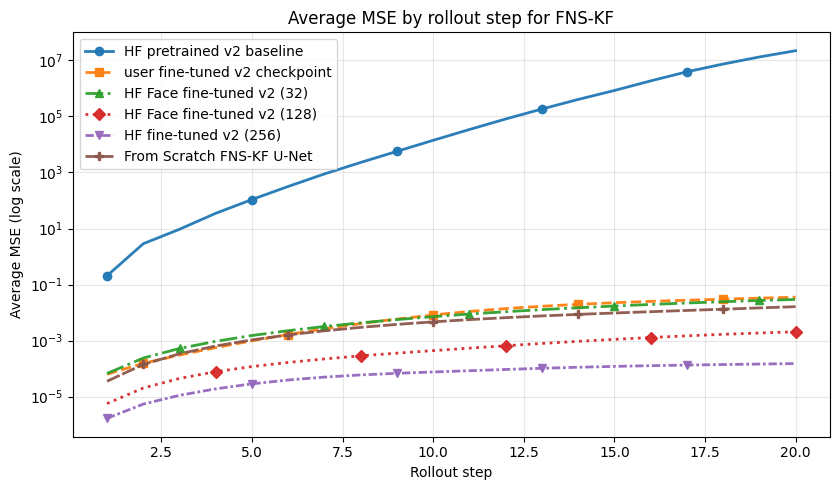

In [19]:
_ = plot_multiple_rollout_mse_curves(
    [
        pretrained_evaluation_outcome["evaluation_path"],
        user_evaluation_outcome["evaluation_path"],
        fns_kf_32_evaluation_outcome["evaluation_path"],
        fns_kf_128_evaluation_outcome["evaluation_path"],
        fns_kf_256_evaluation_outcome["evaluation_path"],
        fns_kf_scratch_evaluation_outcome["evaluation_path"]
    ],
    labels=[
        "HF pretrained v2 baseline",
        "user fine-tuned v2 checkpoint",
        "HF Face fine-tuned v2 (32) ",
        "HF Face fine-tuned v2 (128)",
        "HF fine-tuned v2 (256)",
        "From Scratch FNS-KF U-Net"
    ],
    save_path=comparison_output_dir / "fns_kf_mse_compare.png",
)
